# PW8 - Logistic Regression

**Team:** Noé Berdoz, Michael Strefeler

Our starting levels, the time spent per exercise and the bonus request are in the preamble of `ex1-logistic-regression-stud.ipynb`.

# Exercise 2 - Optional - Classification on MNIST

Using the SciKit Learn toolkit, train a multi-class logistic regression on the MNIST problem and compare the performances with the KNN of PW2.

For the “daring” ones, implement a multi-class version based on your own implementation and run it against MNIST data.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams['figure.figsize'] = (10.0, 10.0)
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

In [2]:
train = pd.read_csv('mnist_train.csv')
X_train = train.drop('label', axis=1).values.reshape(-1,28,28)
y_train = train['label'].values

test = pd.read_csv('mnist_test.csv')
X_test = test.drop('label', axis=1).values.reshape(-1,28,28)
y_test = test['label'].values

In [3]:
print('Training data shape: ', X_train.shape)
print('Training labels shape: ', y_train.shape)
print('Test data shape: ', X_test.shape)
print('Test labels shape: ', y_test.shape)

Training data shape:  (60000, 28, 28)
Training labels shape:  (60000,)
Test data shape:  (10000, 28, 28)
Test labels shape:  (10000,)


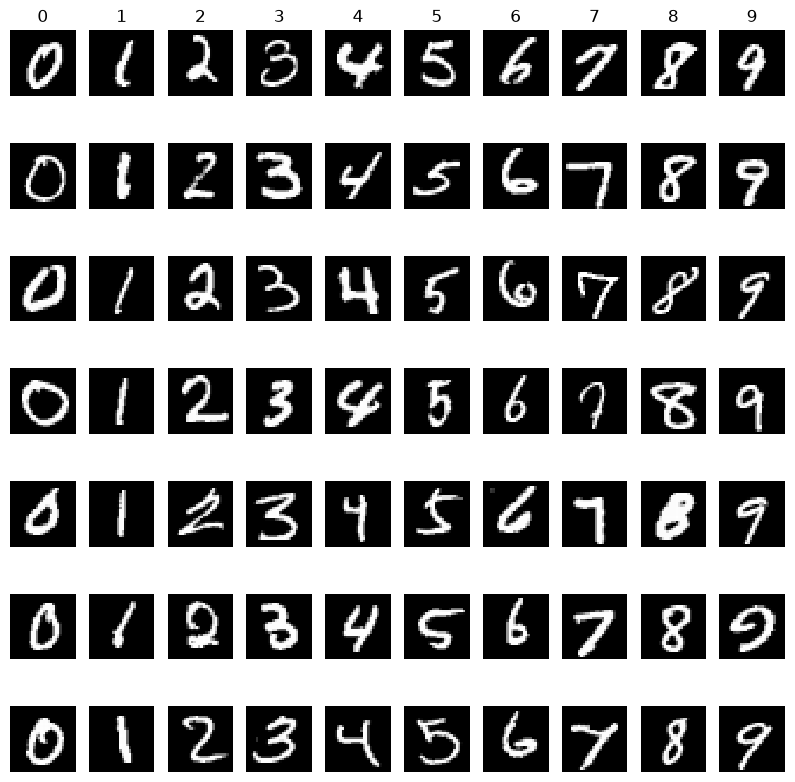

In [4]:
classes = ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']
num_classes = len(classes)
samples_per_class = 7
for y, cls in enumerate(classes): # y and cls takes values from 0-9
    idxs = np.flatnonzero(y_train == y) # gets the indices of samples that corresponds to class y
    idxs = np.random.choice(idxs, samples_per_class, replace=False) # picks randomly samples_per_class indices
    for i, idx in enumerate(idxs):
        plt_idx = i * num_classes + y + 1   # determines the sub-plot index
        plt.subplot(samples_per_class, num_classes, plt_idx)
        plt.imshow(X_train[idx].astype('uint8'))
        plt.axis('off')
        if i == 0:
            plt.title(cls)
plt.show()

In [5]:
# TODO: train and test this data using logistic regression, you can use scikit-learn.
# You can subsample the data for training, because the set is large.
# You may need to put the data back to 1D.

In [6]:
import time

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix
from sklearn.model_selection import cross_val_score
from sklearn.multiclass import OneVsRestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [7]:
# Flatten the images to 1D vectors of 28*28 = 784 pixels (new names, so the cell can be re-run safely)
X_train_flat = X_train.reshape(X_train.shape[0], -1)
X_test_flat = X_test.reshape(X_test.shape[0], -1)
print(X_train_flat.shape, X_test_flat.shape)

(60000, 784) (10000, 784)


### Choosing the regularization strength by cross-validation

We choose the regularization strength in the same way as we chose $k$ for the KNN in PW2, so that the two models can be compared. We run a 5-fold cross-validation on the first 5000 training images to choose $C$, the inverse of the regularization strength. Then we retrain with the best value on the full training set of 60000 images and evaluate the model once on the 10000 test images. `cross_val_score` builds stratified folds, with about the same share of each digit in every fold. These are not the folds of PW2, so further down we run the cross-validation of the KNN again with the same folds.

The model is a `StandardScaler` followed by a `LogisticRegression` with the default L2 penalty and the `lbfgs` solver, which uses a multinomial (softmax) model for multi-class problems. Putting the scaler in a pipeline means it is fitted only on the training folds during cross-validation, so no information from the validation fold leaks into it.

In [8]:
num_training = 5000
X_sub = X_train_flat[:num_training]
y_sub = y_train[:num_training]

num_folds = 5
C_choices = [1e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1, 1]

C_to_accuracies = {}
for C in C_choices:
    model = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=2000))
    C_to_accuracies[C] = cross_val_score(model, X_sub, y_sub, cv=num_folds, scoring="accuracy")

for C in C_choices:
    accs = C_to_accuracies[C]
    print(f"C = {C:<7g} accuracy = {accs.mean():.4f} +/- {accs.std():.4f}  (folds: {np.round(accs, 3)})")

C = 0.0001  accuracy = 0.8230 +/- 0.0113  (folds: [0.807 0.812 0.836 0.83  0.83 ])
C = 0.001   accuracy = 0.8824 +/- 0.0160  (folds: [0.864 0.865 0.888 0.906 0.889])
C = 0.003   accuracy = 0.8970 +/- 0.0150  (folds: [0.884 0.877 0.904 0.919 0.901])
C = 0.01    accuracy = 0.9002 +/- 0.0175  (folds: [0.887 0.874 0.905 0.922 0.913])
C = 0.03    accuracy = 0.8980 +/- 0.0173  (folds: [0.883 0.874 0.902 0.921 0.91 ])
C = 0.1     accuracy = 0.8928 +/- 0.0112  (folds: [0.882 0.881 0.89  0.91  0.901])
C = 1       accuracy = 0.8814 +/- 0.0115  (folds: [0.872 0.868 0.877 0.897 0.893])


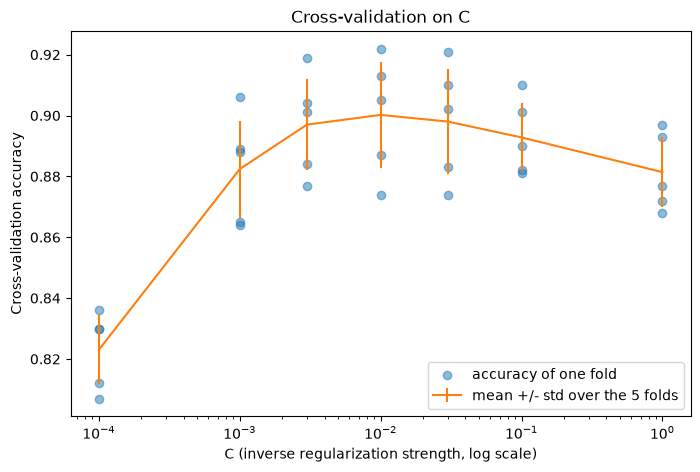

Best C: 0.01


In [9]:
# Same plot as for k in PW2: raw fold accuracies and mean +/- std
plt.figure(figsize=(8, 5))
for i, C in enumerate(C_choices):
    label = "accuracy of one fold" if i == 0 else None
    plt.scatter([C] * num_folds, C_to_accuracies[C], color="tab:blue", alpha=0.5, label=label)

accuracies_mean = np.array([C_to_accuracies[C].mean() for C in C_choices])
accuracies_std = np.array([C_to_accuracies[C].std() for C in C_choices])
plt.errorbar(C_choices, accuracies_mean, yerr=accuracies_std, color="tab:orange", label="mean +/- std over the 5 folds")
plt.xscale("log")
plt.title("Cross-validation on C")
plt.xlabel("C (inverse regularization strength, log scale)")
plt.ylabel("Cross-validation accuracy")
plt.legend()
plt.show()

best_C = C_choices[int(np.argmax(accuracies_mean))]
print(f"Best C: {best_C:g}")

### Training on the full training set and evaluating on the test set

In [10]:
# Retrain with the best C on the 60000 training images, then test once on the 10000 test images
clf = make_pipeline(StandardScaler(), LogisticRegression(C=best_C, max_iter=2000))

tic = time.time()
clf.fit(X_train_flat, y_train)
train_time = time.time() - tic

tic = time.time()
y_test_pred = clf.predict(X_test_flat)
predict_time = time.time() - tic

num_correct = np.sum(y_test_pred == y_test)
num_test = X_test_flat.shape[0]
accuracy = float(num_correct) / num_test
train_accuracy = np.mean(clf.predict(X_train_flat) == y_train)
print(f"Got {int(num_correct)} / {num_test} correct => accuracy: {accuracy}")
print(f"Accuracy on the 60000 training images: {train_accuracy:.4f}")
print(f"Training time: {train_time:.1f} s, prediction time for {num_test} images: {predict_time:.3f} s")

Got 9261 / 10000 correct => accuracy: 0.9261
Accuracy on the 60000 training images: 0.9361
Training time: 1.7 s, prediction time for 10000 images: 0.010 s


In [11]:
print(classification_report(y_test, y_test_pred, digits=4))

              precision    recall  f1-score   support

           0     0.9533    0.9796    0.9663       980
           1     0.9628    0.9797    0.9712      1135
           2     0.9373    0.8983    0.9174      1032
           3     0.9030    0.9129    0.9079      1010
           4     0.9341    0.9379    0.9360       982
           5     0.9041    0.8666    0.8849       892
           6     0.9372    0.9509    0.9440       958
           7     0.9250    0.9241    0.9246      1028
           8     0.8774    0.8891    0.8832       974
           9     0.9181    0.9108    0.9144      1009

    accuracy                         0.9261     10000
   macro avg     0.9252    0.9250    0.9250     10000
weighted avg     0.9260    0.9261    0.9259     10000



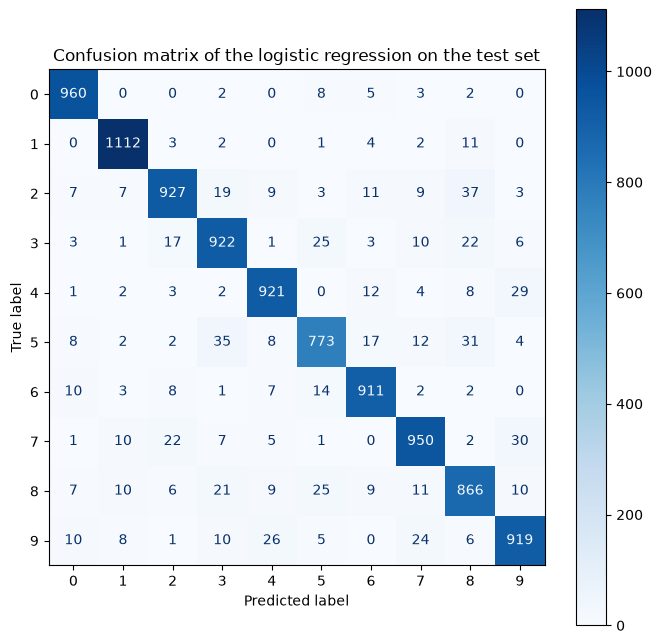

37 images of the digit 2 predicted as 8
35 images of the digit 5 predicted as 3
31 images of the digit 5 predicted as 8


In [12]:
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred, ax=ax, cmap="Blues", colorbar=True)
ax.set_title("Confusion matrix of the logistic regression on the test set")
plt.show()

# The three largest errors, outside the diagonal
cm = confusion_matrix(y_test, y_test_pred)
np.fill_diagonal(cm, 0)
for idx in np.argsort(cm, axis=None)[::-1][:3]:
    true_digit, pred_digit = np.unravel_index(idx, cm.shape)
    print(f"{cm[true_digit, pred_digit]} images of the digit {true_digit} predicted as {pred_digit}")

In the course, we saw how to build a multi-class logistic regression with the one vs rest approach. We train one binary logistic regression per digit, for example 5 against all the other digits, and an image goes to the digit whose classifier gives the highest probability. The `LogisticRegression` above does not do this, because scikit-learn trains a single softmax model for the ten classes. To check our result with the method of the course, we also train ten one vs rest classifiers with `OneVsRestClassifier`, with the same scaler and the same $C$.

In [13]:
# Cross-check with the one vs rest approach of the course, same scaler and same C
ovr = make_pipeline(StandardScaler(), OneVsRestClassifier(LogisticRegression(C=best_C, max_iter=2000)))

tic = time.time()
ovr.fit(X_train_flat, y_train)
ovr_train_time = time.time() - tic

y_test_pred_ovr = ovr.predict(X_test_flat)
num_correct_ovr = np.sum(y_test_pred_ovr == y_test)
print(f"One vs rest: {num_correct_ovr} / {num_test} correct => accuracy: {num_correct_ovr / num_test}")
print(f"Same prediction as the softmax model for {np.sum(y_test_pred_ovr == y_test_pred)} of the {num_test} test images")
print(f"Training time: {ovr_train_time:.1f} s")

One vs rest: 9195 / 10000 correct => accuracy: 0.9195
Same prediction as the softmax model for 9735 of the 10000 test images
Training time: 2.1 s


In PW2 our own KNN with $k = 3$ got 9705 / 10000 correct on the same test images. To compare the times on the same machine and the cross-validation on the same folds, we run the same KNN again with scikit-learn's `KNeighborsClassifier`.

In [14]:
# KNN of PW2 (k = 3), run with scikit-learn so that both models are timed on the same machine
knn = KNeighborsClassifier(n_neighbors=3)

tic = time.time()
knn.fit(X_train_flat, y_train)
knn_train_time = time.time() - tic

tic = time.time()
y_test_pred_knn = knn.predict(X_test_flat)
knn_predict_time = time.time() - tic

num_correct_knn = np.sum(y_test_pred_knn == y_test)
print(f"KNN (k = 3): {num_correct_knn} / {num_test} correct => accuracy: {num_correct_knn / num_test}")
print(f"Training time: {knn_train_time:.3f} s, prediction time for {num_test} images: {knn_predict_time:.2f} s")
print(f"Both models wrong: {np.sum((y_test_pred != y_test) & (y_test_pred_knn != y_test))} images")
print(f"Only the logistic regression wrong: {np.sum((y_test_pred != y_test) & (y_test_pred_knn == y_test))} images")
print(f"Only the KNN wrong: {np.sum((y_test_pred == y_test) & (y_test_pred_knn != y_test))} images")

# Cross-validation of the same KNN on the first 5000 images, with the same folds as the logistic regression above
knn_cv = cross_val_score(KNeighborsClassifier(n_neighbors=3), X_sub, y_sub, cv=num_folds, scoring="accuracy")
print(f"KNN (k = 3), cross-validation on the first 5000 images: {knn_cv.mean():.4f} +/- {knn_cv.std():.4f}  (folds: {np.round(knn_cv, 3)})")

KNN (k = 3): 9705 / 10000 correct => accuracy: 0.9705
Training time: 0.034 s, prediction time for 10000 images: 2.95 s
Both models wrong: 203 images
Only the logistic regression wrong: 536 images
Only the KNN wrong: 92 images
KNN (k = 3), cross-validation on the first 5000 images: 0.9302 +/- 0.0079  (folds: [0.919 0.931 0.936 0.941 0.924])


### Discussion

After retraining on the full 60000 images, the softmax model gets 92.61% accuracy on the 10000 test images. This is higher than the cross-validation score of 90.02%, probably because each cross-validation model was trained on only 4000 images (4 of the 5 folds), while the final model has 15 times more training data (60000 images). On the training images it reaches 93.61%, only 1 point above the test accuracy, so the model overfits very little.

The digits are not all recognized equally well. The recall goes from 86.66% for the 5 to 97.97% for the 1. The largest errors in the confusion matrix are between digits with similar shapes. 37 images of a 2 are predicted as an 8, 35 images of a 5 as a 3 and 31 images of a 5 as an 8.

The one vs rest version of the course gets 91.95%, 0.66 points below the softmax model, and the two models give the same prediction for 9735 of the 10000 test images. So the one vs rest of the course and the softmax of scikit-learn give almost the same result. The softmax model learns the ten classes together and its ten probabilities add up to 1, like with the softmax that is added at the end of a neural network. In one vs rest, each classifier is trained alone.

The KNN of PW2 is clearly more accurate, but the logistic regression is much faster at prediction time.

| | Logistic regression | KNN ($k = 3$) |
|---|---|---|
| Cross-validation on the first 5000 images (same folds) | 90.02% | 93.02% |
| Test accuracy on the 10000 test images | 92.61% | 97.05% |
| Training time on our machine | about 2 seconds | almost no time |
| Prediction time for the 10000 test images on our machine | less than 0.1 seconds | about 3 seconds |

On 536 test images the KNN is right and the logistic regression is wrong, while the opposite happens on only 92 images.

The difference between instance-based and model-based learning, which we saw in the course, explains this. The KNN is instance-based learning. It learns the training images by heart and classifies a new image from the 3 closest ones, so its decision boundary can follow the data very closely. The logistic regression is model-based learning. It learns one weight per pixel and per digit, so it can only separate the digits with linear boundaries in the space of the 784 pixels. As we saw above, the model overfits very little, so the gap with the KNN probably comes from these linear boundaries, which are too simple for MNIST. To bend them we would need new features, like the squares we added in exercise 1c.

The prediction times come from what each model keeps. The logistic regression keeps only 10 x 785 = 7850 weights, while the KNN keeps the 60000 training images and computes the distance from each test image to all of them. In the course we saw that this cpu load on large training sets is a weakness of the KNN. It is also why the KNN trains in almost no time, since it just stores the data.

### Daring part - our own multi-class version

For the daring part, we reuse our own functions from exercise 1 and apply the one vs rest approach of the course by hand. For each digit $k$ we run our gradient ascent with the target $y = 1$ for the images of $k$ and $y = 0$ for all the other images. This gives ten $\theta$ vectors of 785 values, the bias and one weight per pixel. A test image then goes to the digit whose classifier gives the highest $h_\theta(x)$.

In [15]:
# Our functions from exercise 1 (ex1-logistic-regression-stud.ipynb), unchanged
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def hypothesis(X, theta):
    return sigmoid(np.dot(X, theta))

def objective(X, y, theta):
    epsilon = 1e-6
    h = hypothesis(X, theta)
    N = X.shape[0]
    tmp = y * np.log(h + epsilon) + (1 - y) * np.log(1 - h + epsilon)
    return np.sum(tmp) / N

def gradient_ascent(X, y, learning_rate, num_epoch):
    N = X.shape[0]
    D = X.shape[1]
    theta = np.zeros(D)
    J = []
    for epoch in range(num_epoch):
        h = hypothesis(X, theta)
        error = y - h
        gradient = np.dot(error, X) / N
        theta = theta + learning_rate * gradient
        J.append(objective(X, y, theta))
    return theta, J

# New for the 10 classes: one gradient ascent per digit (one vs rest), then the argmax of the 10 scores
def train_one_vs_rest(X, y, learning_rate, num_epoch):
    thetas = []
    J_all = []
    for k in range(10):
        y_k = (y == k) * 1.0
        theta_k, J_k = gradient_ascent(X, y_k, learning_rate, num_epoch)
        thetas.append(theta_k)
        J_all.append(J_k)
    return np.array(thetas), J_all

def predict_one_vs_rest(X, thetas):
    h_all = hypothesis(X, thetas.T)  # one column per digit
    return np.argmax(h_all, axis=1)

The pixels are always between 0 and 255, so we rescale them with min-max, which here is a division by 255. In the course we saw that min-max is the right choice when the bounds are known and there are no outliers. The learning rate of exercise 1, $\alpha = 0.001$, was chosen for two exam scores and not for 784 pixels. We therefore compare a few values of $\alpha$ on a validation set. We train on the first 50000 training images for 300 epochs and measure the accuracy on the last 10000, so the test set is not used for this choice.

In [16]:
# Pixels divided by 255 (min-max rescaling) and a column of ones for the bias
def add_bias(X):
    return np.hstack([np.ones((X.shape[0], 1)), X / 255])

X_own_train = add_bias(X_train_flat)
X_own_test = add_bias(X_test_flat)
print(X_own_train.shape, X_own_test.shape)

# Choice of alpha: train on the first 50000 training images, validate on the last 10000
X_a, y_a = add_bias(X_train_flat[:50000]), y_train[:50000]
X_v, y_v = add_bias(X_train_flat[50000:]), y_train[50000:]

for learning_rate in [0.001, 0.1, 1, 3]:
    thetas_a, _ = train_one_vs_rest(X_a, y_a, learning_rate, num_epoch=300)
    acc_v = np.mean(predict_one_vs_rest(X_v, thetas_a) == y_v)
    print(f"alpha = {learning_rate:<5g} validation accuracy after 300 epochs: {acc_v:.4f}")

(60000, 785) (10000, 785)
alpha = 0.001 validation accuracy after 300 epochs: 0.7575
alpha = 0.1   validation accuracy after 300 epochs: 0.8884
alpha = 1     validation accuracy after 300 epochs: 0.9154
alpha = 3     validation accuracy after 300 epochs: 0.9034


We keep $\alpha = 1$, which gives the best validation accuracy (91.54%). With $\alpha = 0.001$, the value of exercise 1, the steps are so small that the accuracy is only 75.75% after 300 epochs. With $\alpha = 3$ the steps are too long and the accuracy goes down again to 90.34%. We then train the final model on the 60000 training images for 3000 epochs and test it once on the 10000 test images.

Our one vs rest: 9195 / 10000 correct => accuracy: 0.9195
Accuracy on the 60000 training images: 0.9212
Same prediction as scikit-learn's one vs rest for 9841 of the 10000 test images
Training time: 151.1 s


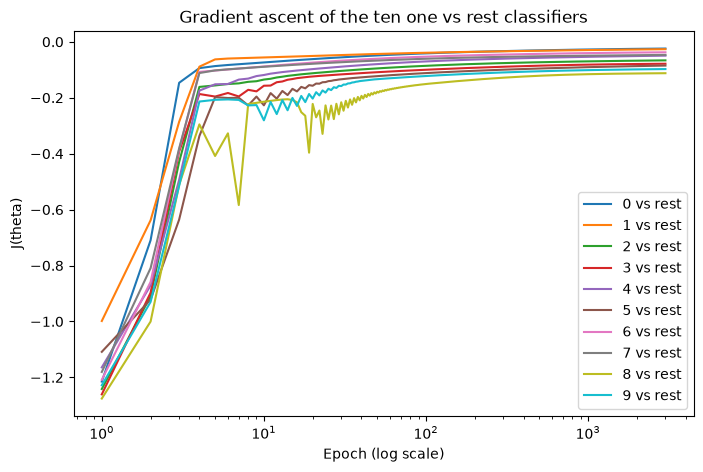

In [17]:
# Final model: alpha = 1 on the 60000 training images, then test once on the 10000 test images
tic = time.time()
thetas_own, J_own = train_one_vs_rest(X_own_train, y_train, learning_rate=1, num_epoch=3000)
own_train_time = time.time() - tic

y_test_pred_own = predict_one_vs_rest(X_own_test, thetas_own)
num_correct_own = np.sum(y_test_pred_own == y_test)
own_train_accuracy = np.mean(predict_one_vs_rest(X_own_train, thetas_own) == y_train)
print(f"Our one vs rest: {num_correct_own} / {num_test} correct => accuracy: {num_correct_own / num_test}")
print(f"Accuracy on the 60000 training images: {own_train_accuracy:.4f}")
print(f"Same prediction as scikit-learn's one vs rest for {np.sum(y_test_pred_own == y_test_pred_ovr)} of the {num_test} test images")
print(f"Training time: {own_train_time:.1f} s")

plt.figure(figsize=(8, 5))
for k in range(10):
    plt.plot(np.arange(1, len(J_own[k]) + 1), J_own[k], label=f"{k} vs rest")
plt.xscale("log")
plt.title("Gradient ascent of the ten one vs rest classifiers")
plt.xlabel("Epoch (log scale)")
plt.ylabel("J(theta)")
plt.legend()
plt.show()

Our own one vs rest gets 91.95% on the test set (9195 / 10000), exactly the same score as scikit-learn's one vs rest. The two models are not identical, because scikit-learn adds a penalty on the weights and uses the z-norm instead of the division by 255, but they give the same prediction for 9841 of the 10000 test images. This is a good check of our code.

The plot shows that $\alpha = 1$ is a long step. With $\theta = 0$ every classifier starts at $J(\theta) = \log(0.5) = -0.69$. This point is not on the plot, because our function saves $J(\theta)$ after each step. After the first step $J(\theta)$ is lower for all of them, because this step is too long. A few curves then go up and down for a while, and after that every curve goes up at each epoch and is almost flat at the end.

On our machine, the training takes about 150 seconds, against a few seconds for scikit-learn's one vs rest, because we run 3000 epochs for each of the ten digits and our function also computes $J(\theta)$ after each step.

In the end our three logistic regressions (the softmax model, scikit-learn's one vs rest and our own one vs rest) all land between 91.95% and 92.61%, far below the 97.05% of the KNN. Our own version also reaches only 92.12% on the training images. Three different implementations give almost the same accuracy, so we think the limit comes from the linear model and not from our code.